<a href="https://colab.research.google.com/github/lamboant01/maie383/blob/main/lab03_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MIAE 383: Lab 3

## Classification and inspection

Work in pairs on one branch, or individually if needed. Each student runs and writes about their own view. Submit individually during the lab, with the upload allowance until 11:25. Duration: 140 minutes.

**Marks:** code 50, analysis 20, memo 20, individual check 10. The lab is worth 5% of the course.

**Submit:** your executed notebook and results.json, with the memo inside the notebook.

Disclose AI explanation/debugging help. Write your analysis and memo yourself. The micro-quiz is individual and ungraded; no AI or partner help.

## Preparation

Sessions 7-9: validation, logistic regression, classification metrics and thresholds. Run preparation.ipynb before the lab.

## Branches

**Mechanical:** Steel plates: distinguish the rare Stains fault from other observed fault types. Every source row is already a fault case; healthy-versus-defective accuracy cannot be inferred.

**Industrial:** SECOM: predict a failed semiconductor process test using 27 anonymized sensor channels. The supplied split follows time order.

**Aerospace:** Hydraulic-component testing: identify the 73% valve condition (near total failure) against settings of 80%, 90% and 100%. Inputs are 16 pressure/flow summaries. This is a component-testing analogy, with no aircraft operational validation. PS1-PS6 are pressure channels (bar); FS1-FS2 are flow channels (L/min). Each cycle supplies a mean and standard deviation for each channel.

The industrial branch can produce no useful event detection. A supported negative conclusion earns full credit. Equal validation costs are also valid; use the supplied tie rule.

## Model and inspection rule

Logistic regression estimates the probability of the recorded event.

- Compare C = 0.1, 1, 10, with and without class weighting.
- Fit imputation and scaling on training data.
- Compare thresholds from 0.05 to 0.95 on validation data.
- Minimize the illustrative cost FP + 20 FN, then test the selected rule.

Report confusion counts, precision, recall, cost and inspection workload. Class weighting affects training; the threshold determines the inspection decision.

## Work plan

| Time | Task |
| --- | --- |
| 08:45-09:00 | Open the kit; enter issued codes and confirm the data |
| 09:00-10:00 | Complete four functions, run their checks and the supplied investigations |
| 10:00-10:45 | Finish the short analysis and individual memo |
| 10:45-10:53 | Micro-quiz (MCQ) |
| 10:53-11:05 | Export, download and verify both submission files |

The allowance to 11:25 is for upload problems. The demonstrator checks individual understanding during the work. If a function still fails after 15 minutes, ask for help and work on a written answer while you wait.

In [1]:
#@title Load supplied libraries and data files
from pathlib import Path
import sys, json, time, zipfile
_expected_lab = 3
_expected_kit_version = 'lab-final-20261017'
_required = ['src/miae383/data.py', 'data/manifest.json', 'data/steel.csv', 'data/secom.csv', 'data/hydraulic.csv']

def _matching_folder(folder):
    if not all((folder/name).is_file() for name in _required):
        return False
    manifest = folder/'kit_manifest.json'
    if not manifest.exists():
        return True
    metadata = json.loads(manifest.read_text())
    return metadata.get('lab') == _expected_lab and metadata.get('version') == _expected_kit_version

def _matching_archive(path):
    try:
        with zipfile.ZipFile(path) as archive:
            if not set(_required).issubset(archive.namelist()):
                return False
            if 'kit_manifest.json' in archive.namelist():
                metadata = json.loads(archive.read('kit_manifest.json'))
                return metadata.get('lab') == _expected_lab and metadata.get('version') == _expected_kit_version
            return path.name == 'course_support.zip'
    except (zipfile.BadZipFile, KeyError, ValueError):
        return False

_archives = [p for p in Path.cwd().glob('*')
             if p.suffix.lower() == '.zip' and _matching_archive(p)]
_search = [Path.cwd()] if _archives else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _search if _matching_folder(p)), None)
if ROOT is None:
    if not _archives:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError('Extract the current Lab 3 student kit and open its notebook from that folder. See START_HERE.pdf.')
        print('Upload the Lab 3 student ZIP.')
        _uploaded = [Path(name) for name in files.upload() if name.lower().endswith('.zip')]
        if len(_uploaded) != 1 or not _matching_archive(_uploaded[0]):
            raise RuntimeError('Upload the current Lab 3 Student Kit ZIP from Moodle. Older kits and re-zipped folders are not supported.')
        _archives = _uploaded
    if len(_archives) != 1:
        raise RuntimeError('Keep one current Lab 3 support ZIP in this runtime.')
    ROOT = Path.cwd().resolve()
    with zipfile.ZipFile(_archives[0]) as archive:
        if any(not (ROOT/name).resolve().is_relative_to(ROOT) for name in archive.namelist()):
            raise RuntimeError('Invalid ZIP path. Request a fresh kit.')
        # Extract runtime support only; do not create a blank notebook beside results.json.
        for member in archive.namelist():
            if member.startswith(('src/', 'data/', 'labs/')) or member == 'kit_manifest.json':
                archive.extract(member, ROOT)
if 'miae383.data' in sys.modules:
    _loaded = Path(sys.modules['miae383.data'].__file__).resolve()
    if not _loaded.is_relative_to(ROOT.resolve()):
        raise RuntimeError('Restart the runtime, then rerun from this lab folder.')
try:
    import otter
except ModuleNotFoundError:
    if 'google.colab' not in sys.modules:
        raise RuntimeError('Install requirements-local.txt first. See START_HERE.pdf.')
    import subprocess
    subprocess.run([sys.executable,'-m','pip','install','-q','otter-grader==6.1.6'],check=True)
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from miae383.identity import ViewContext, is_preview_identity, check_submission_identity
from miae383.data import assigned_view, split_arrays, model_seed
print('Runtime:',sys.version.split()[0], '| NumPy',np.__version__,
      '| pandas',pd.__version__, '| scikit-learn',sklearn.__version__)
print('Setup complete. Continue to Assigned view.')


Upload the Lab 3 student ZIP.


Saving Lab 3 - Student Kit.zip to Lab 3 - Student Kit.zip
Runtime: 3.13.16 | NumPy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1
Setup complete. Continue to Assigned view.


## Assigned view

Enter the issued details **at the start of the lab, before the investigations**. DEMO is for preparation only.

- **STUDENT_TOKEN:** your four-letter token, not your student number.
- **SECTION_ID:** your registered section. Confirm its release code with the demonstrator.
- **BRANCH:** both partners choose the same branch; each student uses their own data view.
- **RELEASE_CODE:** the four-letter code issued for this lab and section.
- **PAIR_ID:** both partners' tokens, alphabetically joined by a hyphen, for example `ABCD-WXYZ`.

Working alone, or partner not here yet: enter only your own token. Correct the label if a partner joins; your results are kept.

Rerunning this cell with the same data details preserves results. Correcting only the pair label also preserves results. A change of token, section, branch or release code requires saving the notebook, restarting and rerunning before updating the answers.

In [29]:
# Enter issued details before starting the assessed work.
LAB_ID = 3
STUDENT_TOKEN = "KBWC" #@param {type:"string"}
SECTION_ID = "AI" #@param ["", "AI", "BI", "CI", "DI", "FI"]
BRANCH = "industrial" #@param ["mechanical", "industrial", "aerospace"]
# Release code: the section code announced by the demonstrator.
RELEASE_CODE = "MWPB" #@param {type:"string"}
# Pair label: your token alone, or both tokens, for example ABCD-WXYZ.
PAIR_ID = "KBWC-ZTUX" #@param {type:"string"}
from miae383.lab_session import load_session
load_session(globals())


Assigned data: section AI; branch industrial; pair KBWC-ZTUX.
Confirm your section and release code with the demonstrator.
Source: secom
Positive event (label 1): process test failure | units: binary class
Split: chronological observed timestamp
Records: training=540, validation=180, test=180
Inputs: sensor_000, sensor_001, sensor_002, sensor_003, sensor_004, sensor_005, sensor_006, sensor_007, sensor_008, sensor_009, sensor_010, sensor_011, sensor_012, sensor_013, sensor_014, sensor_015, sensor_016, sensor_017, sensor_018, sensor_019, sensor_020, sensor_021, sensor_022, sensor_023, sensor_024, sensor_025, sensor_026
Model seed: 717805109


## Four functions

Each comment is one small step, usually one or two lines. Complete the function and run its check. If it fails, read the message, correct the function and rerun the check. Keep the names and arguments. Investigations, plots and export are supplied. Hidden grading tests check the same rules on other inputs.

### make_classifier: 15 points

Return an unfitted pipeline in this order:

1. `SimpleImputer(strategy="median", keep_empty_features=True)`
2. `StandardScaler()`
3. `LogisticRegression(C=C, class_weight="balanced" if weighted else None, max_iter=1500, random_state=383)`

The later fit learns imputation, scaling and classifier parameters from training rows. Larger C means weaker regularization.

In [9]:
def make_classifier(C, weighted):

    # Create a median SimpleImputer with keep_empty_features=True.
  imputer = SimpleImputer(strategy="median", keep_empty_features=True)
    # Create a StandardScaler. The later fit will learn its statistics.
  scaler=StandardScaler()
    # Choose class_weight="balanced" if weighted is True; otherwise use None.
  class_weight = "balanced" if weighted is True else None

    # Create LogisticRegression with C, that class_weight, max_iter=1500 and random_state=383.
  classifier = LogisticRegression(C=C, class_weight=class_weight, max_iter=1500, random_state=383)
    # Return make_pipeline(imputer, scaler, classifier), without fitting it.
  return make_pipeline(imputer, scaler, classifier)
#raise NotImplementedError("Replace this line with your implementation.")


In [10]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab03/public_tests'))
grader.check('make_classifier')


make_classifier results: All test cases passed!

### confusion_counts: 10 points

For matching binary 1D arrays, return integer tn, fp, fn, tp. Raise ValueError for incompatible shape/nonbinary values. Empty matching arrays yield zero counts.

**Useful tools:** `np.asarray`, `.ndim`, `.shape`, `np.isin(array, [0, 1]).all()`, Boolean `&`, and `int(np.sum(...))` for each count. Put parentheses around each comparison before combining it with `&`.

**Small check:** actual `[1, 0, 1, 0]`, predicted `[1, 1, 0, 0]` gives one of each count.

In [12]:
def confusion_counts(y, predicted):

    # Convert y and predicted to NumPy arrays.
  converted_y = np.asarray(y)
  converted_predicted = np.asarray(predicted)

    # Reject non-1D arrays or different shapes with ValueError.
  if converted_y.ndim != 1 or converted_predicted.shape != converted_y.shape:
    raise ValueError("Use matching nonempty 1D arrays.")
    # Reject any value other than 0 or 1. Matching empty arrays are allowed.
  if not np.isin(converted_y, [0, 1]).all() or not np.isin(converted_predicted, [0, 1]).all():
    raise ValueError("Use binary labels.")
    # Count true negatives: actual 0 and p  redicted 0.
  count_t_neg = (converted_y == 0) & (converted_predicted == 0)
  tn = int(np.sum(count_t_neg))
    # Count false positives: actual 0 and predicted 1.
  count_f_pos = (converted_y == 0) & (converted_predicted == 1)
  fp = int(np.sum(count_f_pos))
    # Count false negatives: actual 1 and predicted 0.
  count_f_neg = (converted_y == 1) & (converted_predicted == 0)
  fn = int(np.sum(count_f_neg))
    # Count true positives: actual 1 and predicted 1.
  count_t_pos = (converted_y == 1) & (converted_predicted == 1)
  tp = int(np.sum(count_t_pos))
    # Return a dictionary with keys tn, fp, fn and tp; each value is a Python int.
  return {"tn": tn, "fp": fp, "fn": fn, "tp": tp}
#raise NotImplementedError("Replace this line with your implementation.")


In [13]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab03/public_tests'))
grader.check('confusion_counts')


confusion_counts results: All test cases passed!

### classification_metrics: 10 points

Return precision, recall, f1, accuracy from a valid nonnegative count dictionary. Any zero denominator gives 0.0. Positive class is 1.

**Input:** a dictionary of valid nonnegative counts. You do not need to re-check the labels here; `confusion_counts` handles those.

**Small check:** `tp=2, fp=1, fn=2, tn=5` gives precision 2/3, recall 1/2, F1 4/7 and accuracy 7/10. If all four counts are zero, return 0.0 for every metric.

In [14]:
def classification_metrics(counts):
    # Read tn, fp, fn and tp from the supplied valid count dictionary.
    read_tn=counts["tn"]
    read_fp=counts["fp"]
    read_fn=counts["fn"]
    read_tp=counts["tp"]

    # Compute precision = tp / (tp + fp), or 0.0 if its denominator is zero.
    precision=read_tp/(read_tp+read_fp) if (read_tp+read_fp)!=0 else 0.0

    # Compute recall = tp / (tp + fn), or 0.0 if its denominator is zero.
    recall=read_tp/(read_tp+read_fn) if (read_tp+read_fn)!=0 else 0.0
    # Compute f1 = 2*tp / (2*tp + fp + fn), or 0.0 if its denominator is zero.
    f1=2*read_tp/(2*read_tp+read_fp+read_fn) if (2*read_tp+read_fp+read_fn)!=0 else 0.0
    # Compute accuracy = (tp + tn) / total, or 0.0 if total is zero.
    accuracy=(read_tp+read_tn)/(read_tp+read_tn+read_fp+read_fn) if (read_tp+read_tn+read_fp+read_fn)!=0 else 0.0
    # Return the four values with keys precision, recall, f1 and accuracy.
    return {"precision": precision, "recall": recall, "f1": f1, "accuracy": accuracy}
    #raise NotImplementedError("Replace this line with your implementation.")


In [15]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab03/public_tests'))
grader.check('classification_metrics')


classification_metrics results: All test cases passed!

### select_threshold: 15 points

Search thresholds 0.05,0.10,...,0.95. Predict positive when p>=threshold. Minimize cost_fp*FP+cost_fn*FN on validation data; break ties by the smallest threshold.

**Return:** one threshold, not predictions or a fitted model. Reuse the saved probabilities for every threshold; do not call `.fit` in this function.

`min` on a list of `(cost, threshold)` pairs compares cost first and threshold second.

**Small check:** actual `[0, 1]`, probabilities `[0.40, 0.70]`, and costs 1 and 5 have zero cost at thresholds 0.45 through 0.70. Return **0.45**, the smallest tied threshold.

The input checks and grid are supplied. Complete only the three decision steps, using the cost arguments passed to the function.

In [24]:
def select_threshold(y, probability, cost_fp, cost_fn):
    # Supplied input checks; keep these lines.
    y = np.asarray(y)
    p = np.asarray(probability, dtype=float)
    if y.ndim != 1 or p.shape != y.shape or y.size == 0:
        raise ValueError("Use matching nonempty 1D arrays.")
    if not np.isin(y, [0, 1]).all() or not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError("Use binary labels and finite probabilities in [0, 1].")
    if not np.isfinite([cost_fp, cost_fn]).all() or min(cost_fp, cost_fn) < 0:
        raise ValueError("Use finite nonnegative costs.")

    thresholds = np.arange(1, 20) / 20
    results=[]
    # 1. For each threshold, form predictions with p >= threshold.
    for threshold in thresholds:
        predictions = (p >= threshold).astype(int)
        # 2. Use confusion_counts to calculate cost_fp * FP + cost_fn * FN.
        count = confusion_counts(y, predictions)
        cost = cost_fp * count["fp"] + cost_fn * count["fn"]
        # 3. Return the smallest threshold among those with minimum cost.
        results.append((cost, threshold))
    return float(min(results)[1])

In [25]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab03/public_tests'))
grader.check('select_threshold')


select_threshold results: All test cases passed!

## Inspection decision: 5 analysis points

Complete the labelled lines below in at most 40 words.

**Positive event:** Process test failure.

**Inspection action:** Review sensor anomalies and check test logs.

**Reason for the higher missed-event cost:** Missed failures lead to damaged downstream products, which is costlier than a manual check.

## Supplied investigations

Run these cells in order after the four function checks. Edit the labelled response cells. Keep the supplied experiment code and data partitions.

### Investigation 1: Define the event and costs

Check the counts for the training and validation partitions. Label 1 is the positive event printed by Assigned view.

In [30]:
_begin_stage(1)
# Keep the assigned partitions. These are the illustrative costs.
(Xtr, ytr), (Xva, yva), (Xte, yte) = split_arrays(view)
cost_fp, cost_fn = 1.0, 20.0
partition_rows = []
for name, labels in [("training", ytr), ("validation", yva)]:
    partition_rows.append({
        "partition": name, "records": len(labels),
        "positive_events": int(labels.sum()),
    })
print(pd.DataFrame(partition_rows).to_string(index=False))
print("Positive event:", view["metadata"]["target_name"])
print("Illustrative costs: FP =", cost_fp, "and FN =", cost_fn)
print("Missing training measurements:", int(Xtr.isna().sum().sum()))
_finish_stage(1)


 partition  records  positive_events
  training      540               44
validation      180                7
Positive event: process test failure
Illustrative costs: FP = 1.0 and FN = 20.0
Missing training measurements: 35


### Investigation 2: Compare models and thresholds on validation data

Six classifiers are fitted. Each compares 19 thresholds using one saved validation probability array. Use the stated FP/FN costs. Lowering the threshold can catch more events and raise more false alarms. The table has one row per model, showing its best threshold and cost. C0.1_weightedTrue means C=0.1 with class weighting.

In [31]:
_begin_stage(2)
candidates, rows = {}, []
# Six fits: three C settings, each with and without class weighting.
for C in [0.1, 1.0, 10.0]:
    for weighted in [False, True]:
        name = f"C{C}_weighted{weighted}"
        fitted = make_classifier(C, weighted).fit(Xtr, ytr)
        # Reuse this array for all 19 threshold comparisons.
        probabilities = fitted.predict_proba(Xva)[:, 1]
        threshold = select_threshold(yva, probabilities, cost_fp, cost_fn)
        validation_counts = confusion_counts(
            yva, (probabilities >= threshold).astype(int)
        )
        cost = cost_fp * validation_counts["fp"] + cost_fn * validation_counts["fn"]
        candidates[name] = (fitted, threshold)
        rows.append({
            "model": name, "threshold": threshold,
            "validation_cost": cost, **validation_counts,
        })
experiment = pd.DataFrame(rows)
print(experiment.to_string(index=False))
_finish_stage(2, {"validation_comparison": rows})


              model  threshold  validation_cost  tn  fp  fn  tp
 C0.1_weightedFalse       0.30            120.0 173   0   6   1
  C0.1_weightedTrue       0.80            123.0 170   3   6   1
 C1.0_weightedFalse       0.35            120.0 173   0   6   1
  C1.0_weightedTrue       0.85            124.0 169   4   6   1
C10.0_weightedFalse       0.35            120.0 173   0   6   1
 C10.0_weightedTrue       0.85            125.0 168   5   6   1


### Investigation 3: Lock the classifier and decision rule

The next cell picks the model with the smallest validation cost. Exact model-cost ties use alphabetical model names; threshold ties within one model use the smallest threshold. It prints the locked model and threshold. Record them before the test audit.

In [32]:
_begin_stage(3)
# Resolve exact model-cost ties alphabetically, using unrounded values.
chosen = min(rows, key=lambda row: (row["validation_cost"], row["model"]))["model"]
model, threshold = candidates[chosen]
selected_row = next(row for row in rows if row["model"] == chosen)
print("Locked model:", chosen)
print("Locked threshold:", threshold)
print("Validation cost:", selected_row["validation_cost"])
_finish_stage(3, {"selected_model": chosen, "threshold": threshold})


Locked model: C0.1_weightedFalse
Locked threshold: 0.3
Validation cost: 120.0


### Validation choice

Before running the test audit, complete these three fields from Investigation 3:

Model: C0.1_weightedFalse

Threshold: 0.3

Validation cost: 120.0

This record is not an additional marked response.

### Investigation 4: Evaluate decisions on the test partition

Read TP, FP, FN and TN using the branch's positive event. Use the comparison table for the marked error analysis.

In [33]:
_begin_stage(4)
# Predict once with the already fitted, validation-selected classifier.
p = model.predict_proba(Xte)[:, 1]
counts = confusion_counts(yte, (p >= threshold).astype(int))
default_counts = confusion_counts(yte, (p >= 0.5).astype(int))
print("Test records:", len(yte), "| positive events:", int(yte.sum()))
test_results = {
    "training_positive_feature_mean": float(Xtr.iloc[np.flatnonzero(ytr == 1), 0].mean()),
    "validation_positive_feature_mean": float(Xva.iloc[np.flatnonzero(yva == 1), 0].mean()),
    "test_positive_feature_mean": float(Xte.iloc[np.flatnonzero(yte == 1), 0].mean()),
    **counts, **classification_metrics(counts),
}
print("Selected-threshold counts:", counts)
print("Default-threshold counts:", default_counts)
_finish_stage(4, test_results)


Test records: 180 | positive events: 9
Selected-threshold counts: {'tn': 167, 'fp': 4, 'fn': 9, 'tp': 0}
Default-threshold counts: {'tn': 167, 'fp': 4, 'fn': 9, 'tp': 0}


### Investigation 5: Compare the resulting workload and errors

Read inspections as TP + FP. Compare the selected and 0.5 thresholds on the same test observations. The inspect_none and inspect_all rows show the two extremes; do not choose a new threshold from this test table.

In [34]:
_begin_stage(5)
# These fixed reference policies describe test workload; do not select again.
policies = [
    ("selected", counts),
    ("default_0.5", default_counts),
    ("inspect_none", confusion_counts(yte, np.zeros(len(yte), dtype=int))),
    ("inspect_all", confusion_counts(yte, np.ones(len(yte), dtype=int))),
]
comparison = []
for policy, policy_counts in policies:
    comparison.append({
        "policy": policy, **policy_counts, **classification_metrics(policy_counts),
        "error_cost": cost_fp * policy_counts["fp"] + cost_fn * policy_counts["fn"],
        "inspections": policy_counts["tp"] + policy_counts["fp"],
    })
print(pd.DataFrame(comparison).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
_finish_stage(5, {"test_decision_comparison": comparison})


      policy  tn  fp  fn  tp  precision  recall     f1  accuracy  error_cost  inspections
    selected 167   4   9   0     0.0000  0.0000 0.0000    0.9278    184.0000            4
 default_0.5 167   4   9   0     0.0000  0.0000 0.0000    0.9278    184.0000            4
inspect_none 171   0   9   0     0.0000  0.0000 0.0000    0.9500    180.0000            0
 inspect_all   0 171   0   9     0.0500  1.0000 0.0952    0.0500    171.0000          180


### Investigation 6: Plot the confusion matrix

Read the confusion matrix by row and column. Use this figure in Data and decision record.

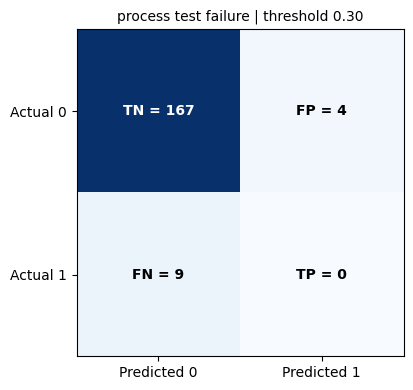

In [35]:
_begin_stage(6)
matrix = np.array([[counts["tn"], counts["fp"]], [counts["fn"], counts["tp"]]])
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.imshow(matrix, cmap="Blues")
ax.set_xticks([0, 1], ["Predicted 0", "Predicted 1"])
ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
for (row, column), value in np.ndenumerate(matrix):
    ax.text(column, row, f"{[['TN', 'FP'], ['FN', 'TP']][row][column]} = {value}", ha="center", va="center",
            color="white" if value > matrix.max() / 2 else "black", fontweight="bold")
ax.set_title(f"{view['metadata']['target_name']} | threshold {threshold:.2f}", fontsize=10)
fig.tight_layout()
plt.show()
_finish_stage(6)


## Classification errors: 7 analysis points

Complete the labelled lines below in at most 70 words. Refer to supplied tables and figures; do not copy them.

**Selected versus default rule: cite counts, recall, precision and cost from Investigation 5:** The selected and default rules are identical. Both have 0 TP, 4 FP, 9 FN, and 167 TN. Precision and recall are 0.00%. The total cost is 184.0.

**Inspection workload and missed events:** The workload requires 4 inspections (TP + FP). We missed 9 events (FN).

**Comparison with the cheaper of inspect-none and inspect-all:** Inspect-none is cheaper than our model, costing 180.0 (versus 184.0).

## Validation comparison: 4 analysis points

Complete the labelled lines below in at most 50 words. Refer to supplied tables and figures; do not copy them.

**Baseline (C0.1_weightedFalse) and one C or class-weight change:** Changing C to 10.0 (C10.0_weightedFalse).

**Two validation costs:** The validation cost remains exactly 120.0 for both models.

**Conclusion, including an unchanged result:** Increasing C has no effect. The optimal threshold remains at 0.35 with identical performance.

## Data and decision record: 4 analysis points

Complete the labelled lines below in at most 40 words. Refer to supplied tables and figures; do not copy them.

**Source and positive label:** SECOM dataset; process test failure.

**Missing training measurements:** 35 missing values in total.

**Threshold and confusion-matrix reference:** Threshold 0.30. In Investigation 6, TN=167, FP=4, FN=9, and TP=0.

## Individual engineering memo: 20 points, at most 250 words

Use the five headings below. Refer to the analysis and output labels instead of repeating calculations. Write your own recommendation.

### Decision: 3 points, maximum 40 words

**Your response:** Do not deploy the model. Use the "inspect_none" policy for all incoming manufacturing processes, as the model lacks predictive power.

### Evidence: 5 points, maximum 60 words

**Your response:** The selected model (C0.1_weightedFalse, threshold 0.30) had a validation cost of 120.0 (Investigation 3). On the test set, it had a recall of 0.00 and cost 184.0 (Investigation 5).

### Interpretation: 5 points, maximum 60 words

**Your response:** The model missed all 9 actual failures (recall = 0) and added 4 false alarms. This results in a test cost of 184.0, which is worse than the inspect_none baseline cost of 180.0.

### Limitations: 5 points, maximum 50 words

**Your response:** The failure class is extremely rare (only 5% of the test set (9/180)). The model fails to find generalizable patterns, leading to critical missed defects.

### Next Action: 2 points, maximum 40 words

**Your response:** Validate future candidate models on a new dataset. We must achieve a minimum recall of more or less 80% and a cost below 180.0 before deployment.

## Contribution and assistance

**My contribution and a check I performed (40 words maximum):** i contributed to this lab equally.

**AI tool, help requested, where used, and how I checked it (60 words maximum, or None):** AI was used to improve grammar and syntax and also code syntax and fix up dumb errors.

**Other sources used (links or None):** None

The individual check is oral with the demonstrator, worth 10 points. Explain your own code and one result without partner or AI help. If working alone, describe a check of your own work.

Technical explanation /4: use your counts to explain an FP/FN trade-off and why the threshold is chosen on validation data. Contribution/review /3: identify your work and a check you performed. Next step /3: justify an independent check before using the rule.

## Micro-quiz: 8 minutes, 0 course marks

Answer three MCQs on Moodle when the demonstrator opens the activity. Work individually without AI or partner help.

## Save and submit

1. Run the export cell. Check the reported investigation count and file status.
2. Save the **executed notebook**, with outputs and written answers, and **results.json**.
3. In Colab, use **File > Download > Download .ipynb** for the notebook. Download results.json from the Files panel. A runtime reset can remove unsaved files.
4. Upload both files to Gradescope. Open the submitted notebook preview and confirm that your code, outputs and answers are present. Check the timestamp and file names.

Include the labelled analysis responses, five memo sections, contribution and AI disclosure. After a restart, run all cells from the top and upload the original ZIP when asked; then export again. Save the notebook regularly so typed answers are retained.

If unfinished, set `ALLOW_INCOMPLETE = True` in the export cell and submit the attempted work. It records missing investigations. Upload the current results.json, not a `.previous.json` backup.

In [36]:
# Set True only when deliberately submitting unfinished work.
ALLOW_INCOMPLETE = False #@param {type:"boolean"}
from miae383.lab_session import export_results
payload = export_results(globals(), [1, 2, 3, 4, 5, 6], ALLOW_INCOMPLETE)


Wrote results.json: complete; 6/6 investigations; 15 result fields.
Upload results.json and the executed notebook. Export does not check written answers or assign marks.
